# 03 - Feature engineering

**But** : transformer les coups de chaque joueur en variables numériques (features) qui pourraient aider à prédire
son Elo. Pas de modèle ici : on construit les features et on regarde, pour chacune, si elle est liée à l'Elo.
Les modèles viendront dans le notebook suivant.

Point de départ : `blitz_180_joueurs.parquet` (notebook 01), 1 ligne par joueur et par partie.
Le code des features est dans `src/utils/features.py` (réutilisé par le notebook modèle).

**Règle anti-fuite** : on n'utilise que **les coups du joueur**. Les coups de l'adversaire renseignent sur le niveau
de l'adversaire, donc sur celui du joueur (Elo blanc/noir corrélés à 0,96).

Pour chaque famille de features :
1. calcul ;
2. distribution (valeurs aberrantes, valeurs manquantes) ;
3. lien avec l'Elo : moyenne par tranche d'Elo + corrélation de Spearman.

Familles : **1. pendule**, **2. coups (SAN)**, **3. fin de partie**, **4. ouverture**, puis **5. redondance** et
**6. table finale**.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import plotly.express as px
import polars as pl
import polars.selectors as cs

from utils.features import COUPS, OUVERTURE, PENDULE, ajoute_fin, ajoute_temps, calcule_features

IN_PATH = Path("../Data/blitz_180_joueurs.parquet")
OUT_PATH = Path("../Data/blitz_180_features.parquet")

pl.Config.set_tbl_rows(30)
plt.rcParams["figure.dpi"] = 110

Deux petites fonctions d'analyse, utilisées pour chaque famille :
- `courbes` : moyenne de chaque feature par tranche d'Elo de 100 points (tranches de moins de 1000 lignes retirées) ;
- `spearman` : corrélation de rang avec l'Elo (capte les relations monotones, même non linéaires) + % de valeurs manquantes.

In [2]:
def courbes(df, cols, titre):
    t = (
        df.with_columns(tranche=pl.col("elo") // 100 * 100)
        .group_by("tranche")
        .agg(n=pl.len(), *[pl.col(c).cast(pl.Float64).mean() for c in cols])
        .filter(pl.col("n") >= 1000)
        .sort("tranche")
    )
    nrows = math.ceil(len(cols) / 4)
    fig, axes = plt.subplots(nrows, 4, figsize=(14, 2.8 * nrows), sharex=True, squeeze=False)
    for ax, c in zip(axes.flat, cols):
        ax.plot(t["tranche"], t[c], marker=".")
        ax.set_title(c, fontsize=10)
        ax.grid(alpha=0.3)
    for ax in axes.flat[len(cols):]:
        ax.axis("off")
    fig.suptitle(titre)
    fig.supxlabel("Elo")
    fig.tight_layout()
    plt.show()


def spearman(df, cols):
    return pl.DataFrame({
        "feature": cols,
        "spearman": [df.select(pl.corr(pl.col(c).cast(pl.Float64), "elo", method="spearman")).item() for c in cols],
        "pct_null": [round(df[c].null_count() / df.height * 100, 1) for c in cols],
    }).sort(pl.col("spearman").abs(), descending=True)

In [3]:
joueurs = ajoute_temps(pl.read_parquet(IN_PATH))
print(joueurs.shape)
joueurs.select("joueur", "elo", "couleur", "cadence", "score", "termination", "san", "clk", "temps").head(3)

(1023985, 13)


joueur,elo,couleur,cadence,score,termination,san,clk,temps
str,i32,str,str,f64,str,list[str],list[i32],list[i32]
"""DOMI60FR""",1735,"""White""","""180+2""",0.5,"""Normal""","[""d4"", ""c4"", … ""Kc4""]","[180, 181, … 88]","[null, 1, … 1]"
"""Q8KSA""",1991,"""White""","""180+0""",1.0,"""Normal""","[""e4"", ""Nf3"", … ""Qe6+""]","[180, 179, … 27]","[null, 1, … 2]"
"""MiltonMorales""",2224,"""White""","""180+0""",0.0,"""Normal""","[""e4"", ""Nc3"", … ""h5""]","[180, 179, … 169]","[null, 1, … 1]"


## 1. Pendule

`clk` = temps restant après chaque coup. On en déduit `temps` = secondes passées sur chaque coup :

`temps[i] = clk[i-1] - clk[i] + incrément` (0 s en 180+0, 2 s en 180+2). Le 1er coup vaut null : la pendule
ne tourne pas encore.

| feature | définition | idée |
|---|---|---|
| `t_ouverture` | temps moyen par coup, coups 1-10 | les forts connaissent leurs ouvertures |
| `t_milieu` | idem, coups 11-25 (null si non atteint) | c'est là qu'on réfléchit |
| `t_finale` | idem, coups 26+ (null si non atteint) | |
| `pct_rapides` | % de coups joués en ≤ 1 s | prémoves, automatismes |
| `pct_longs` | % de coups joués en ≥ 10 s | grosses réflexions |
| `t_max` / `coup_t_max` | plus longue réflexion et à quel coup | |
| `cv_temps` | écart-type / moyenne du temps par coup | régularité |
| `pct_zeitnot` | % de coups joués avec < 20 s restantes | gestion du temps |
| `temps_restant_fin` | temps restant au dernier coup | |

In [4]:
# Un exemple : les 12 premiers coups d'un joueur
joueurs.select(coup=pl.col("san").list.head(12), clk=pl.col("clk").list.head(12), temps=pl.col("temps").list.head(12)).head(1).explode(pl.all()).transpose(include_header=True)

column,column_0,column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11
str,str,str,str,str,str,str,str,str,str,str,str,str
"""coup""","""d4""","""c4""","""cxd5""","""Qxd4""","""e4""","""Bb5+""","""Nf3""","""Qd2""","""Qe2""","""Kf1""","""Nc3""","""Qxe7+"""
"""clk""","""180""","""181""","""181""","""181""","""180""","""177""","""176""","""174""","""174""","""172""","""163""","""163"""
"""temps""",null,"""1""","""2""","""2""","""3""","""5""","""3""","""4""","""2""","""4""","""11""","""2"""


In [5]:
pendule = joueurs.select("elo", "cadence", **PENDULE)
pendule.drop("elo", "cadence").describe()

statistic,t_ouverture,t_milieu,t_finale,pct_rapides,pct_longs,t_max,coup_t_max,cv_temps,pct_zeitnot,temps_restant_fin
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1.023985e6,1.017961e6,729225.0,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023982e6,1.023985e6,1.023985e6
"""null_count""",0.0,6024.0,294760.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0
"""mean""",2.478528,5.404728,3.979936,0.330443,0.098182,19.95549,19.406348,1.078198,0.055022,66.825873
"""std""",1.799184,2.734198,2.5476,0.150627,0.084962,12.74249,8.452773,0.318187,0.115235,50.381949
"""min""",0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0
"""25%""",1.333333,3.5,2.434783,0.222222,0.034483,12.0,13.0,0.868028,0.0,19.0
"""50%""",2.0,4.866667,3.4,0.321429,0.08,17.0,18.0,1.024266,0.0,62.0
"""75%""",3.111111,6.733333,4.823529,0.428571,0.142857,25.0,24.0,1.223404,0.030303,107.0
"""max""",21.666667,184.0,123.0,1.0,1.0,187.0,119.0,6.276586,0.979167,320.0


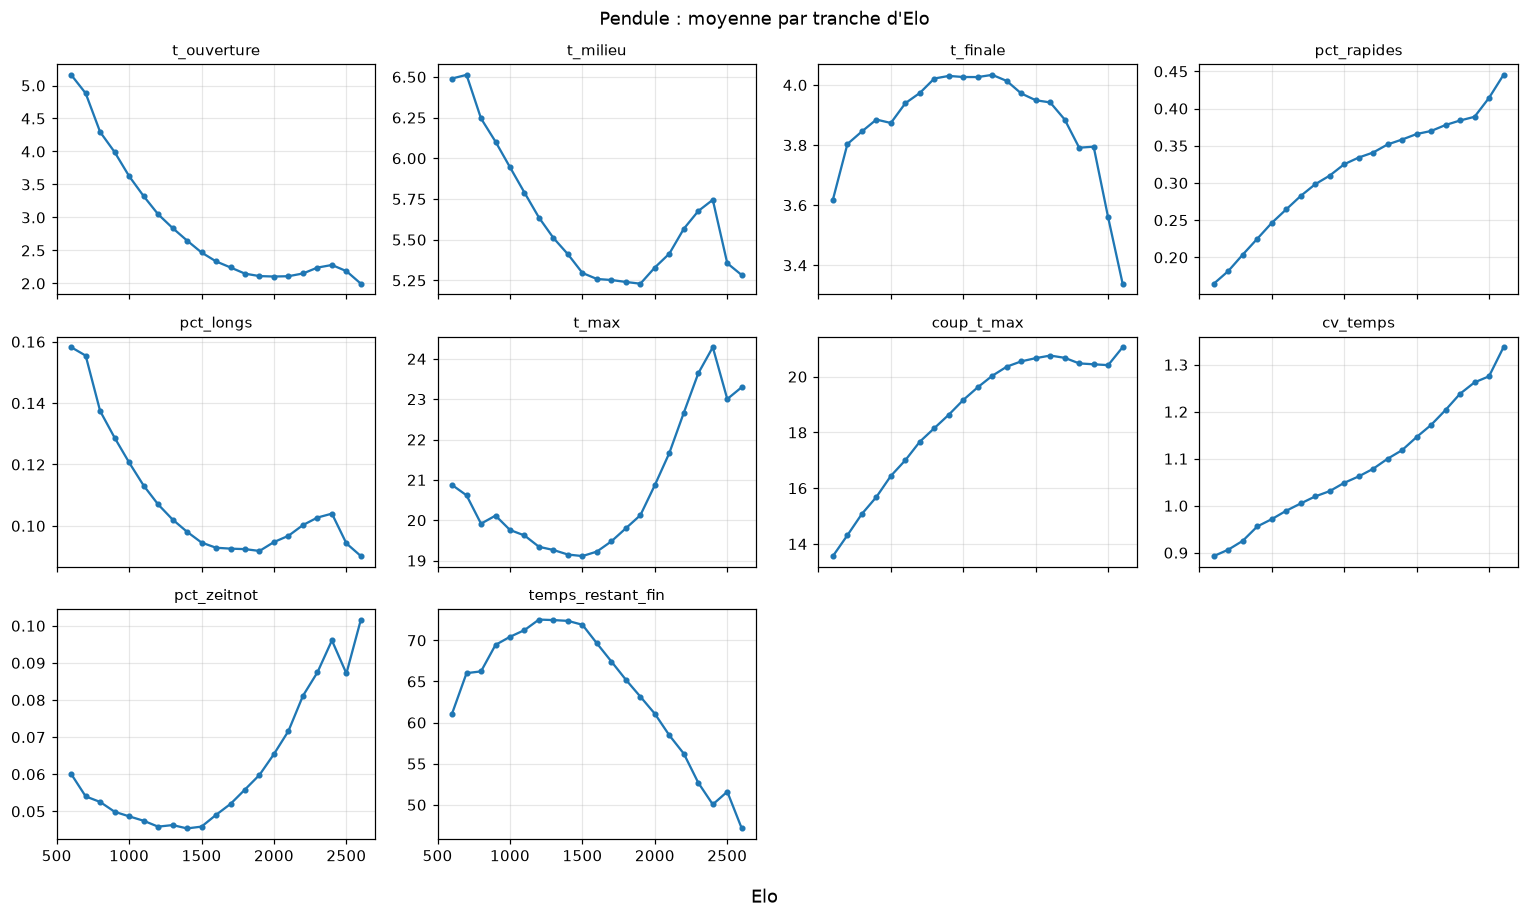

feature,spearman,pct_null
str,f64,f64
"""t_ouverture""",-0.270865,0.0
"""pct_rapides""",0.248073,0.0
"""cv_temps""",0.227315,0.0
"""coup_t_max""",0.157052,0.0
"""temps_restant_fin""",-0.095782,0.0
"""pct_zeitnot""",0.073568,0.0
"""t_max""",0.064912,0.0
"""t_milieu""",-0.045689,0.6
"""pct_longs""",-0.036592,0.0


In [6]:
courbes(pendule, list(PENDULE), "Pendule : moyenne par tranche d'Elo")
spearman(pendule, list(PENDULE))


**Relations monotones** (les plus utiles) :
- `t_ouverture` : 5,2 s → 2,0 s par coup ; `pct_rapides` : 17 % → 45 % : les forts jouent leur ouverture « de mémoire ».
- `cv_temps` : 0,9 → 1,35 : les forts ont un rythme **irrégulier** (très vite quand c'est évident, longtemps sur les
  coups critiques), les faibles passent à peu près le même temps sur chaque coup. C'est la 3ᵉ feature la plus corrélée.
- `coup_t_max` : la plus longue réflexion arrive vers le coup 14 chez les faibles, vers le coup 21 chez les forts
  (les faibles « bloquent » dès l'ouverture, les forts au milieu de partie).

**Relations en U** : `t_milieu`, `t_max`, `pct_longs`, `pct_zeitnot`, `temps_restant_fin`. Les débutants et les
très forts prennent du temps au milieu de partie, pour des raisons différentes. Spearman sous-estime ces features :
un modèle à arbres pourra mieux les utiliser.

**Peu utile** : `t_finale` (relation faible, et null pour 29 % des lignes : parties de moins de 26 coups).
Attention : l'absence de `t_finale` est elle-même une information (partie courte = joueur plutôt faible) :
on la gardera comme « valeur manquante » plutôt que de la remplacer bêtement.


### 1.1 La cadence change-t-elle la gestion du temps ?

Avec +2 s par coup, on a plus de temps : à Elo égal, les features de pendule devraient différer entre 180+0 et 180+2.

In [7]:
par_cadence = (
    pendule.with_columns(tranche=pl.col("elo") // 100 * 100)
    .group_by("tranche", "cadence")
    .agg(n=pl.len(), *[pl.col(c).mean() for c in ["t_ouverture", "t_milieu", "pct_zeitnot"]])
    .filter(pl.col("n") >= 500)
    .unpivot(index=["tranche", "cadence"], on=["t_ouverture", "t_milieu", "pct_zeitnot"], variable_name="feature")
    .sort("tranche")
)
fig = px.line(par_cadence, x="tranche", y="value", color="cadence", facet_col="feature", markers=True, height=350,
              title="Pendule selon la cadence, à Elo égal")
fig.update_yaxes(matches=None, showticklabels=True)
fig.show()


Oui, nettement : à Elo égal, en 180+2 on passe ~1,2 s de plus par coup dans l'ouverture et ~2,6 s de plus au milieu
de partie (l'incrément est presque entièrement « dépensé »). Les zeitnots sont aussi plus fréquents en 180+2 chez les
forts (ils comptent sur l'incrément pour jouer jusqu'au bout).

→ Les features de pendule **ne sont pas comparables entre cadences** : la `cadence` doit toujours être donnée au modèle
(un arbre gère ça tout seul ; pour une régression linéaire on pourra normaliser les features par cadence).


## 2. Les coups (SAN)

Rappel SAN : `e4` = pion, `Nf3` = cavalier (N), `B` = fou, `R` = tour, `Q` = dame, `K` = roi,
`x` = prise, `+` = échec, `#` = mat, `O-O` / `O-O-O` = petit / grand roque, `=Q` = promotion.
Tout se lit directement dans le texte, sans échiquier.

| feature | définition |
|---|---|
| `pct_captures`, `pct_echecs` | % de coups avec `x`, avec `+` |
| `pct_pions`, `pct_cavalier`, `pct_fou`, `pct_tour`, `pct_dame`, `pct_roi` | % de coups joués avec chaque pièce |
| `petit_roque`, `grand_roque` | le joueur a-t-il roqué de ce côté ? |
| `coup_du_roque` | à quel coup (null si pas de roque) |
| `dame_precoce` | la dame a bougé dans les 5 premiers coups (erreur classique de débutant) |
| `n_promotions` | nombre de promotions |

In [8]:
coups = joueurs.select("elo", **COUPS)
coups.drop("elo").describe()

statistic,pct_captures,pct_echecs,pct_pions,pct_cavalier,pct_fou,pct_tour,pct_dame,pct_roi,petit_roque,grand_roque,coup_du_roque,dame_precoce,n_promotions
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,846488.0,1.023985e6,1.023985e6
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,177497.0,0.0,0.0
"""mean""",0.238231,0.063114,0.291367,0.187069,0.162011,0.123933,0.126856,0.081662,0.684813,0.133675,10.218166,0.115832,0.084729
"""std""",0.063353,0.068897,0.087512,0.087658,0.07458,0.091862,0.090854,0.095283,null,null,4.133861,null,0.328389
"""min""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0
"""25%""",0.2,0.0,0.230769,0.121212,0.106383,0.055556,0.057971,0.0,null,null,7.0,null,0.0
"""50%""",0.235294,0.045455,0.285714,0.175439,0.151515,0.111111,0.111111,0.04878,null,null,9.0,null,0.0
"""75%""",0.275862,0.095238,0.34375,0.24,0.206897,0.177778,0.179487,0.12766,null,null,12.0,null,0.0
"""max""",0.769231,0.722222,1.0,0.933333,0.75,0.729412,0.8,0.812081,1.0,1.0,48.0,1.0,8.0


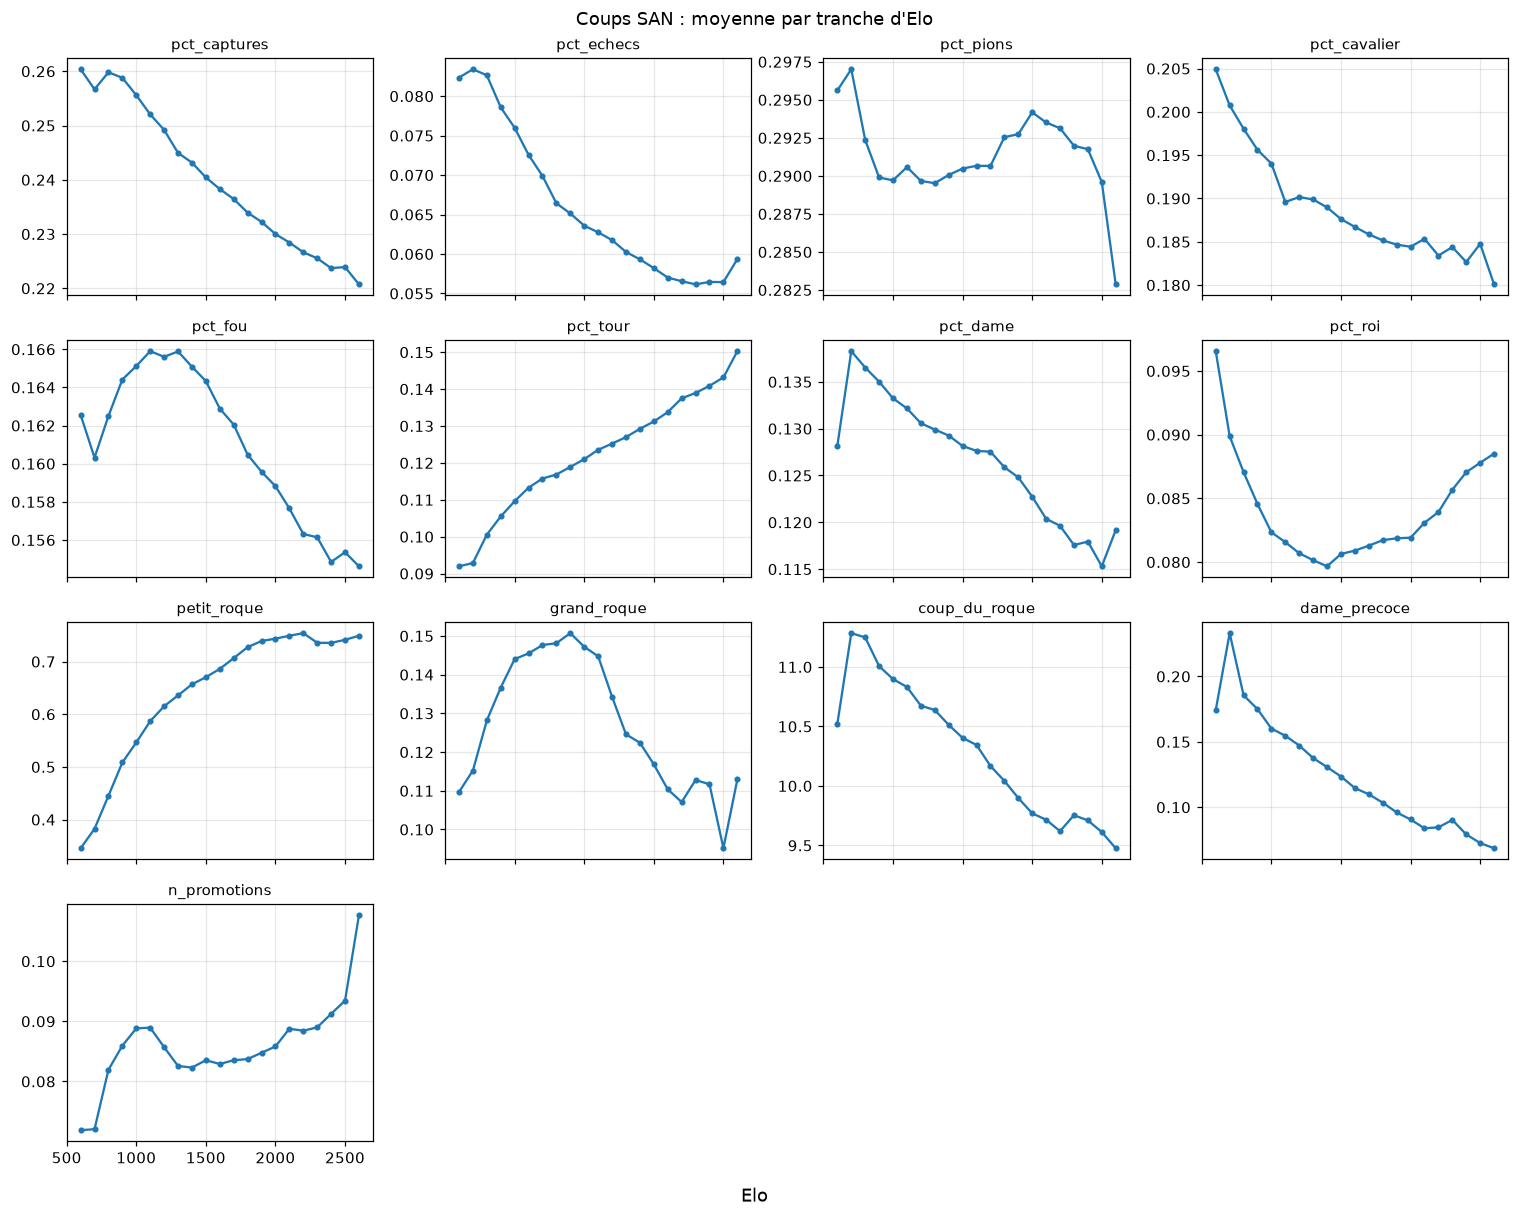

feature,spearman,pct_null
str,f64,f64
"""petit_roque""",0.12282,0.0
"""pct_captures""",-0.119861,0.0
"""pct_tour""",0.095775,0.0
"""coup_du_roque""",-0.08695,17.3
"""dame_precoce""",-0.072008,0.0
"""pct_roi""",0.044011,0.0
"""pct_echecs""",-0.043788,0.0
"""grand_roque""",-0.036676,0.0
"""pct_fou""",-0.031499,0.0


In [9]:
courbes(coups, list(COUPS), "Coups SAN : moyenne par tranche d'Elo")
spearman(coups, list(COUPS))


**Relations monotones** :
- les faibles **prennent** et font **échec** plus souvent (`pct_captures` 26 % → 22 %, `pct_echecs` 8 % → 6 %) et
  jouent plus le cavalier et la dame ;
- les forts jouent plus la **tour** (9 % → 15 %) : leurs parties durent plus longtemps et vont plus souvent en finale ;
- **roque** : `petit_roque` 35 % → 75 %, et il arrive plus tôt (`coup_du_roque` 11 → 9,5) ;
- `dame_precoce` : 23 % → 7 % : l'erreur classique du débutant se voit bien.

**Non monotones** : `pct_fou` et `grand_roque` (en ∩, maximum vers 1200-1600), `pct_roi` (en U : le roi bouge
beaucoup chez les débutants, et en finale chez les forts).

**Inutiles** : `pct_pions` (plat autour de 29 %) et `n_promotions` (événement rare) : |ρ| < 0,02.
Même chose pour `pct_dame` (ρ = -0,02) : la courbe baisse, mais l'écart entre tranches (13,8 % → 11,5 %) est minuscule
comparé à la dispersion d'une partie à l'autre. **Une courbe de moyennes qui bouge ne suffit pas, il faut que l'écart
soit grand devant la dispersion.**


## 3. Fin de partie

`fin` = comment la partie s'est terminée, **du point de vue du joueur** :

| `fin` | règle |
|---|---|
| `nulle` | résultat 1/2-1/2 |
| `gagne_au_temps` / `perd_au_temps` | `Termination = Time forfeit` |
| `mat_donne` | le dernier coup du joueur contient `#` |
| `mat_recu` | le dernier coup de l'adversaire contient `#` (seule info adverse utilisée, elle décrit la partie) |
| `adv_abandonne` / `a_abandonne` | partie gagnée / perdue sans mat ni temps = abandon |
| `inconnu` | partie perdue mais la ligne de l'adversaire a été filtrée (Elo provisoire…) : mat ou abandon ? |

Plus `n_coups` : nombre de coups du joueur.

In [10]:
fin = ajoute_fin(joueurs).select("elo", "fin", n_coups=pl.col("san").list.len())
fin.group_by("fin").agg(n=pl.len(), pct=(pl.len() / fin.height * 100).round(1), elo_moyen=pl.col("elo").mean().round()).sort("n", descending=True)

fin,n,pct,elo_moyen
str,u32,f64,f64
"""adv_abandonne""",240600,23.5,1728.0
"""a_abandonne""",232951,22.7,1719.0
"""gagne_au_temps""",129032,12.6,1688.0
"""perd_au_temps""",127600,12.5,1676.0
"""mat_donne""",119802,11.7,1629.0
"""mat_recu""",114272,11.2,1617.0
"""nulle""",44718,4.4,1753.0
"""inconnu""",15010,1.5,1559.0


In [11]:
fins = (
    fin.with_columns(tranche=pl.col("elo") // 200 * 200)
    .group_by("tranche", "fin")
    .agg(n=pl.len())
    .with_columns(total=pl.col("n").sum().over("tranche"))
    .filter(pl.col("total") >= 1000)
    .with_columns(pct=(pl.col("n") / pl.col("total") * 100).round(1))
    .sort("tranche")
)
ordre = ["mat_donne", "adv_abandonne", "gagne_au_temps", "nulle", "perd_au_temps", "a_abandonne", "mat_recu", "inconnu"]
fig = px.bar(fins, x="tranche", y="pct", color="fin", category_orders={"fin": ordre},
             title="Comment finissent les parties, selon l'Elo (% par tranche de 200)")
fig.show()

In [12]:
spearman(fin, ["n_coups"])

feature,spearman,pct_null
str,f64,f64
"""n_coups""",0.151797,0.0



- **Mats** : 14-18 % des parties chez les faibles → 6-8 % chez les forts. Les forts **abandonnent** quand la position
  est perdue (abandons : ~25 % → ~57 %) et font plus de **nulles** (4 % → 10 %).
- Pertes au temps : un peu moins fréquentes chez les forts.
- `n_coups` (ρ = 0,15) : les forts jouent des parties plus longues.

⚠️ Deux pièges :
- `fin` mélange le **mode** de fin (mat / abandon / temps / nulle) et le **résultat** (gagné / perdu). Le résultat
  seul est peu informatif (appariement par Elo, cf. notebook 01) ; c'est le mode qui porte l'information.
- `inconnu` a un Elo moyen bas (1559) uniquement parce que l'adversaire a été filtré comme Elo provisoire (~1500) :
  c'est un **artefact du nettoyage**, pas une info sur le jeu. À traiter comme valeur manquante.


## 4. Ouverture

- `premier_coup` : le 1er coup **du joueur** (pour les Noirs, c'est leur réponse au 1er coup blanc) ;
- `eco_lettre` : grande famille d'ouverture du code ECO (A = ouvertures de flanc, B = défenses semi-ouvertes dont
  la Sicilienne, C = `e4 e5` et Française, D = `d4 d5`, E = défenses indiennes). L'ECO dépend des coups des deux joueurs,
  mais il décrit la partie, comme `n_coups`.

Ce sont des variables **catégorielles** : pas de Spearman, on compare l'Elo moyen par catégorie.

In [13]:
ouverture = joueurs.select("elo", "couleur", **OUVERTURE)
(
    ouverture.group_by("couleur", "premier_coup")
    .agg(n=pl.len(), elo_moyen=pl.col("elo").mean().round(), elo_std=pl.col("elo").std().round())
    .with_columns(pct=(pl.col("n") / pl.col("n").sum().over("couleur") * 100).round(1))
    .filter(pl.col("pct") >= 1)
    .sort("couleur", "n", descending=[False, True])
)

couleur,premier_coup,n,elo_moyen,elo_std,pct
str,str,u32,f64,f64,f64
"""Black""","""e5""",129297,1570.0,338.0,25.3
"""Black""","""d5""",109873,1654.0,340.0,21.5
"""Black""","""c5""",67621,1807.0,319.0,13.2
"""Black""","""e6""",52577,1709.0,332.0,10.3
"""Black""","""Nf6""",43099,1881.0,348.0,8.4
"""Black""","""c6""",39394,1728.0,335.0,7.7
"""Black""","""d6""",21173,1726.0,358.0,4.1
"""Black""","""g6""",20222,1706.0,331.0,3.9
"""Black""","""b6""",10605,1646.0,298.0,2.1


In [14]:
ouverture.group_by("eco_lettre").agg(n=pl.len(), elo_moyen=pl.col("elo").mean().round(), elo_std=pl.col("elo").std().round()).sort("eco_lettre")

eco_lettre,n,elo_moyen,elo_std
str,u32,f64,f64
"""A""",256579,1723.0,352.0
"""B""",318258,1721.0,338.0
"""C""",285647,1603.0,344.0
"""D""",145186,1695.0,349.0
"""E""",18315,1961.0,329.0



L'ouverture discrimine bien les niveaux :
- Blancs : `e4` (58 %, Elo moyen 1663) < `d4` (1722) < `c4` / `Nf3` (~1820), et `e3` est typique des faibles (1553) ;
- Noirs : `e5` (1570) et `d5` (1654) sont les réponses des faibles, `c5` (Sicilienne, 1807) et `Nf6` (1881) celles des forts ;
- ECO : C (`e4 e5`, 1603) est la famille la plus faible, E (défenses indiennes, 1961) la plus forte.

Jusqu'à 300 points d'écart entre catégories, mais l'écart-type **à l'intérieur** de chaque catégorie reste ~340 :
utile, mais loin d'être suffisant seul.
Pour le modèle : one-hot encoding, en regroupant les premiers coups rares (< 1 %) dans « autre ».


## 5. Redondance entre features

Deux features très corrélées entre elles apportent à peu près la même information. Ce n'est pas grave pour un modèle
à arbres, mais ça rend une régression linéaire instable et ses coefficients illisibles. On calcule la matrice de
corrélation de Spearman entre toutes les features numériques (sur un échantillon de 200k lignes, largement suffisant).

In [15]:
feats = calcule_features(joueurs.drop("temps"))
num = feats.select((cs.numeric() | cs.boolean()) - cs.by_name("elo")).columns
ech = feats.sample(200_000, seed=0)

matrice = pl.DataFrame({
    a: [ech.select(pl.corr(pl.col(a).cast(pl.Float64), pl.col(b).cast(pl.Float64), method="spearman")).item() for b in num]
    for a in num
})
fig = px.imshow(matrice.to_numpy(), x=num, y=num, color_continuous_scale="RdBu_r", zmin=-1, zmax=1, height=750,
                title="Corrélation de Spearman entre features")
fig.show()

In [16]:
# Paires très corrélées (|rho| >= 0.6)
(
    matrice.with_columns(feature_a=pl.Series(num))
    .unpivot(index="feature_a", variable_name="feature_b", value_name="rho")
    .filter(pl.col("feature_a") < pl.col("feature_b"), pl.col("rho").abs() >= 0.6)
    .sort(pl.col("rho").abs(), descending=True)
)

feature_a,feature_b,rho
str,str,f64
"""pct_longs""","""t_milieu""",0.794906
"""pct_zeitnot""","""temps_restant_fin""",-0.754872
"""pct_longs""","""t_max""",0.721853
"""t_max""","""t_milieu""",0.71757
"""cv_temps""","""t_max""",0.685721
"""n_coups""","""temps_restant_fin""",-0.671492
"""pct_rapides""","""t_ouverture""",-0.620143
"""n_coups""","""pct_roi""",0.601952



Aucune paire n'est quasi identique (max |ρ| = 0,79). Les liens attendus :
- `pct_longs` / `t_milieu` / `t_max` / `cv_temps` : toutes mesurent les « grosses réflexions » ;
- `pct_zeitnot` / `temps_restant_fin` : deux façons de voir la fin de pendule ;
- `pct_rapides` / `t_ouverture` (ρ = -0,62) : liées mais pas identiques, les deux méritent d'être gardées.

→ On garde tout pour l'instant. Pour la régression linéaire, on pourra retirer `pct_longs` et `t_max`
si les coefficients sont instables.


## 6. Table finale

In [17]:
recap = spearman(feats, num)
fig = px.bar(recap.sort(pl.col("spearman").abs()), x="spearman", y="feature", orientation="h", height=700,
             title="Corrélation de Spearman de chaque feature avec l'Elo")
fig.show()
recap

feature,spearman,pct_null
str,f64,f64
"""t_ouverture""",-0.270865,0.0
"""pct_rapides""",0.248073,0.0
"""cv_temps""",0.227315,0.0
"""coup_t_max""",0.157052,0.0
"""n_coups""",0.151797,0.0
"""petit_roque""",0.12282,0.0
"""pct_captures""",-0.119861,0.0
"""temps_restant_fin""",-0.095782,0.0
"""pct_tour""",0.095775,0.0


In [18]:
feats.write_parquet(OUT_PATH)
print(feats.shape)
feats.head(3)

(1023985, 32)


game_id,joueur,elo,couleur,cadence,fin,n_coups,t_ouverture,t_milieu,t_finale,pct_rapides,pct_longs,t_max,coup_t_max,cv_temps,pct_zeitnot,temps_restant_fin,pct_captures,pct_echecs,pct_pions,pct_cavalier,pct_fou,pct_tour,pct_dame,pct_roi,petit_roque,grand_roque,coup_du_roque,dame_precoce,n_promotions,premier_coup,eco_lettre
str,str,i32,str,str,str,u32,f64,f64,f64,f64,f64,i32,u32,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64,f64,bool,bool,u32,bool,u32,str,str
"""IMOSvErG""","""DOMI60FR""",1735,"""White""","""180+2""","""nulle""",50,2.888889,4.0,4.16,0.285714,0.122449,14,14,0.944098,0.0,88,0.28,0.14,0.28,0.1,0.06,0.26,0.08,0.22,false,false,null,true,0,"""d4""","""D"""
"""bs18a5LO""","""Q8KSA""",1991,"""White""","""180+0""","""adv_abandonne""",43,1.444444,6.733333,2.166667,0.309524,0.095238,24,19,1.240782,0.0,27,0.209302,0.046512,0.209302,0.093023,0.116279,0.232558,0.302326,0.023256,true,false,9,false,0,"""e4""","""C"""
"""YXYiz29z""","""MiltonMorales""",2224,"""White""","""180+0""","""a_abandonne""",14,0.777778,1.0,null,0.846154,0.0,3,10,1.06212,0.0,169,0.142857,0.0,0.428571,0.142857,0.214286,0.0,0.142857,0.071429,false,false,null,false,0,"""e4""","""B"""



## Bilan

`blitz_180_features.parquet` : 1 023 985 lignes, **24 features numériques** + **5 catégorielles**
(`couleur`, `cadence`, `fin`, `premier_coup`, `eco_lettre`), plus `game_id`, `joueur` (pour le split) et `elo` (cible).

**Les plus prometteuses** (|ρ| avec l'Elo) :
1. pendule : `t_ouverture` (0,27), `pct_rapides` (0,25), `cv_temps` (0,23), `coup_t_max` (0,16) ;
2. partie : `n_coups` (0,15), mode de fin (mats chez les faibles, abandons et nulles chez les forts) ;
3. style : `petit_roque` (0,12), `pct_captures` (0,12), `pct_tour` (0,10), `dame_precoce` (0,07) ;
4. ouverture : jusqu'à 300 points d'écart d'Elo moyen entre premiers coups.

**Probablement inutiles** : `pct_pions`, `pct_dame`, `n_promotions`, `t_finale`.

**À retenir pour le notebook modèle** :
- aucune feature seule ne dépasse |ρ| = 0,27 → tout l'enjeu est de les **combiner** ;
- plusieurs relations en U → comparer régression linéaire et modèle à arbres (`HistGradientBoosting`) ;
- la `cadence` est indispensable (elle décale toutes les features de pendule) ;
- valeurs manquantes informatives (`t_finale`, `coup_du_roque`) : les arbres les gèrent tels quels ;
  pour la régression linéaire, imputer + ajouter un indicateur « manquant » ;
- catégorielles en one-hot (premiers coups rares regroupés), `inconnu` de `fin` = manquant ;
- split train/test **par joueur** ; métriques : MAE (principale), R², MAE par tranche d'Elo.
